<a href="https://colab.research.google.com/github/anisasaputri027-art/tugas-ilp-kelompok/blob/main/tugas_ilp_phy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

DAFTAR INSTRUKSI
Instruksi 1: ADD R1, ['R2', 'R3']
Instruksi 2: SUB R4, ['R1', 'R5']
Instruksi 3: MUL R2, ['R6', 'R7']
Instruksi 4: DIV R1, ['R8', 'R9']
----------------------------------------

 HASIL DETEKSI HAZARD
[RAW Hazard] Instruksi 2 membaca 'R1' yang ditulis oleh Instruksi 1
[WAR Hazard] Instruksi 3 menulis ke 'R2' yang dibaca oleh Instruksi 1
[WAW Hazard] Instruksi 4 menulis ke 'R1' yang juga ditulis oleh Instruksi 1
[WAR Hazard] Instruksi 4 menulis ke 'R1' yang dibaca oleh Instruksi 2
----------------------------------------

 MENAMPILKAN DEPENDENCY GRAPH


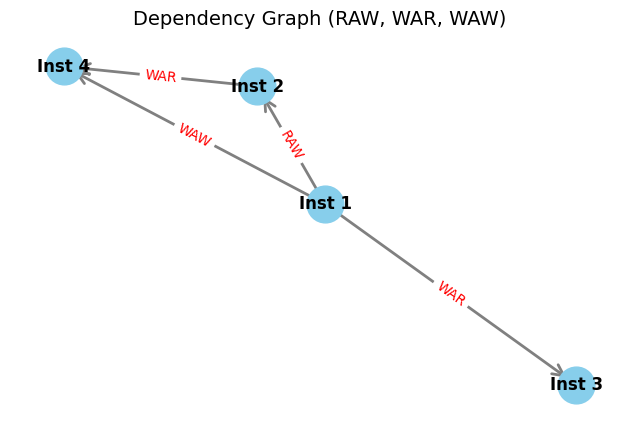

In [ ]:
# Import library untuk visualisasi dependency graph
import matplotlib.pyplot as plt
import networkx as nx

# 1. DEFINISI KASUS INSTRUKSI
# Anda bisa mengubah urutan atau register instruksi di sini untuk menguji RAW, WAR, atau WAW.
instructions = [
    {'id': 1, 'op': 'ADD', 'dest': 'R1', 'src': ['R2', 'R3']},
    {'id': 2, 'op': 'SUB', 'dest': 'R4', 'src': ['R1', 'R5']},  # RAW terhadap R1 dari Inst 1
    {'id': 3, 'op': 'MUL', 'dest': 'R2', 'src': ['R6', 'R7']},  # WAR terhadap R2 dari Inst 1
    {'id': 4, 'op': 'DIV', 'dest': 'R1', 'src': ['R8', 'R9']},  # WAW terhadap R1 dari Inst 1
]

print("DAFTAR INSTRUKSI" )
for inst in instructions:
    print(f"Instruksi {inst['id']}: {inst['op']} {inst['dest']}, {inst['src']}")
print("-" * 40)

# 2. FUNGSI DETEKSI HAZARD (RAW, WAR, WAW)
def detect_hazards(insts):
    dependencies = []

    for i in range(len(insts)):
        for j in range(i + 1, len(insts)):
            i1 = insts[i]
            i2 = insts[j]

            # 1. RAW (Read After Write): i2 membaca register yang ditulis oleh i1
            if i1['dest'] in i2['src']:
                print(f"[RAW Hazard] Instruksi {i2['id']} membaca '{i1['dest']}' yang ditulis oleh Instruksi {i1['id']}")
                dependencies.append((f"Inst {i1['id']}", f"Inst {i2['id']}", 'RAW'))

            # 2. WAR (Write After Read): i2 menulis ke register yang dibaca oleh i1
            if i2['dest'] in i1['src']:
                print(f"[WAR Hazard] Instruksi {i2['id']} menulis ke '{i2['dest']}' yang dibaca oleh Instruksi {i1['id']}")
                dependencies.append((f"Inst {i1['id']}", f"Inst {i2['id']}", 'WAR'))

            # 3. WAW (Write After Write): i2 menulis ke register yang sama yang ditulis oleh i1
            if i1['dest'] == i2['dest']:
                print(f"[WAW Hazard] Instruksi {i2['id']} menulis ke '{i1['dest']}' yang juga ditulis oleh Instruksi {i1['id']}")
                dependencies.append((f"Inst {i1['id']}", f"Inst {i2['id']}", 'WAW'))

    return dependencies

print("\n HASIL DETEKSI HAZARD")
detected_deps = detect_hazards(instructions)
print("-" * 40)

# 3. MEMBUAT DEPENDENCY GRAPH
def draw_dependency_graph(dependencies):
    G = nx.DiGraph()

    # Tambahkan edge beserta tipe hazard sebagai label garis
    for source, target, haz_type in dependencies:
        G.add_edge(source, target, label=haz_type)

    plt.figure(figsize=(8, 5))
    pos = nx.spring_layout(G, seed=42)

    # Gambar nodes dan edges
    nx.draw_networkx_nodes(G, pos, node_size=700, node_color='skyblue')
    nx.draw_networkx_edges(G, pos, edgelist=G.edges(), edge_color='gray', width=2, arrowstyle='->', arrowsize=20)
    nx.draw_networkx_labels(G, pos, font_size=12, font_weight='bold')

    # Tambahkan label jenis hazard di atas garis panah
    edge_labels = {(u, v): d['label'] for u, v, d in G.edges(data=True)}
    nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_color='red', font_size=10)

    plt.title("Dependency Graph (RAW, WAR, WAW)", fontsize=14)
    plt.axis('off')
    plt.show()

print("\n MENAMPILKAN DEPENDENCY GRAPH")
draw_dependency_graph(detected_deps)